# Notebook 1: Logistic regression through the frozen pipeline

**Owner:** Person 1. **Model:** logistic regression (cheapest model, CPU only).

This notebook runs the logistic-regression slice of the experiment grid through the shared core (`core.py`, built by Notebook 0). It does **only the pre-shift part** of the protocol:

1. Load E1 data (train + held-out validation). **OOD / test data is never loaded here.**
2. Sanity checks: C sweep on E1 validation only, and the counterfactual realism check.
3. Smoke test of the full LR path.
4. Run the grid, write the frozen scores file (refuses to overwrite), and copy it as `scores_lr.csv`.
5. Optional: run OOD evaluation and analysis for LR alone, gated behind a switch and only after the freeze.

The merge notebook pools `scores_lr.csv` with the other three models' files and runs the OOD evaluation and analysis.

**Kaggle setup:** Nothing needs to be attached. If you do add Notebook 0's committed output (Add Input, then Notebook Output), its `core.py` is used when it is complete; otherwise the copy embedded in the first cell is written to `/kaggle/working/core.py`. Turn Internet on the first time so MNIST can be downloaded. Run as a committed version (Save Version) so `/kaggle/working` persists.


In [1]:
# Embedded copy of Notebook 0's core.py. It is written to disk only if no usable core.py is attached.
CORE_EMBEDDED = r'''
import os, json, time, hashlib, itertools, pickle, shutil, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, t as t_dist
from itertools import combinations
from math import factorial
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, mutual_info_score
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
# Data globals (set by load_data). Scoring notebooks call load_data(include_test=False),
# so test_x / test_y stay None and OOD data is mechanically unavailable before the freeze.
train_x = train_y = val_x = val_y = test_x = test_y = None

def load_data(root=None, include_test=False, seed=SEED):
    """Load binary (even/odd) MNIST with the same 80/20 train/val split as Notebook 0."""
    global train_x, train_y, val_x, val_y, test_x, test_y
    import glob
    from torchvision import datasets
    cands = [root] if root else []
    cands += ["/kaggle/working/data", *sorted(glob.glob("/kaggle/input/*/data")),
              *sorted(glob.glob("/kaggle/input/*/*/data")), "./data"]
    found = next((c for c in cands if c and os.path.isdir(os.path.join(c, "MNIST", "raw"))), None)
    download = found is None
    root = found or (root or "/kaggle/working/data")
    tr = datasets.MNIST(root=root, train=True, download=download)
    xa, ya = tr.data.numpy(), (tr.targets.numpy() % 2).astype(np.int64)
    idx = np.random.default_rng(seed).permutation(len(xa))
    cut = int(0.8 * len(idx))
    train_x, train_y = xa[idx[:cut]], ya[idx[:cut]]
    val_x, val_y = xa[idx[cut:]], ya[idx[cut:]]
    if include_test:
        te = datasets.MNIST(root=root, train=False, download=download)
        test_x, test_y = te.data.numpy(), (te.targets.numpy() % 2).astype(np.int64)
    else:
        test_x = test_y = None
    return {"train": len(train_x), "val": len(val_x), "test": None if test_x is None else len(test_x)}


# ===== data generator =====
ATTRS = ["color", "marker_tl", "marker_br"]
PATCH = {"marker_tl": (slice(1, 4), slice(1, 4)),     # top-left 3x3
         "marker_br": (slice(24, 27), slice(24, 27))} # bottom-right 3x3

def make_multi_attr_mnist(images, labels, corrs, seed=0):
    """corrs: dict attr -> label correlation (0 = independent decoy)."""
    rng = np.random.default_rng(seed)
    gray = images.astype(np.float32) / 255.0
    n = len(labels)
    out = np.zeros((n, 3, 28, 28), dtype=np.float32)
    attrs = {}
    for a in ATTRS:
        c = corrs.get(a, 0.0)
        match = rng.random(n) < (1 + c) / 2
        attrs[a] = np.where(match, labels, 1 - labels).astype(np.int64)
    out[attrs["color"] == 0, 0] = gray[attrs["color"] == 0]   # red
    out[attrs["color"] == 1, 1] = gray[attrs["color"] == 1]   # green
    for a, (r, c) in PATCH.items():                           # markers: blue channel only
        out[attrs[a] == 1, 2, r, c] = 1.0
    return out, attrs


# ===== interventions =====
def intervene(images, attr):
    x = images.copy()
    if attr == "color":
        x[:, [0, 1]] = images[:, [1, 0]]                 # swap red/green
    elif attr in PATCH:
        r, c = PATCH[attr]
        x[:, 2, r, c] = 1.0 - images[:, 2, r, c]         # toggle marker on/off
    elif attr == "null":
        pass                                             # do-nothing control
    else:
        raise ValueError(attr)
    return x


# ===== registry =====
def build_registry(labels, attrs, threshold=0.5, design_corrs=None):
    """
    Register spuriousness from the experiment design, not noisy sample correlation.
    Convention: strictly greater than threshold is spurious; exactly threshold is not.
    Observed sample correlations are retained as diagnostics.
    """
    reg = {}
    for a, v in attrs.items():
        observed = float(np.corrcoef(labels, v)[0, 1])
        designed = float(design_corrs[a]) if design_corrs is not None and a in design_corrs else observed
        reg[a] = {
            "train_corr": observed,
            "design_corr": designed,
            "spurious": abs(designed) > threshold
        }
    return reg

flat = lambda x: x.reshape(len(x), -1)


# ===== scores =====
def sensitivity_score(model, X, attr):
    """Main score (Person 2's job): fraction of predictions that flip."""
    p0 = model.predict(flat(X))
    p1 = model.predict(flat(intervene(X, attr)))
    return float(np.mean(p0 != p1))

def label_corr_score(labels, attrs, attr):
    """Data-only baseline."""
    return abs(float(np.corrcoef(labels, attrs[attr])[0, 1]))

def mutual_information_score(labels, attrs, attr):
    """Data-only baseline: mutual information between training labels and a
    training attribute (discrete, computed on E1 training data)."""
    return float(mutual_info_score(np.asarray(labels).astype(int),
                                   np.asarray(attrs[attr]).astype(int)))

def grouped_attribute_permutation_score(model, X, y, attr_values, attr,
                                        n_repeats=5, seed=12345):
    """Grouped permutation importance on held-out validation data.
    Shuffle one attribute across examples, rebuild that attribute in the images,
    and measure the accuracy drop.  Score = baseline acc - mean permuted acc.
    (Different from intervene(), which toggles the attribute within each example.)"""
    X = np.asarray(X); y = np.asarray(y)
    current = np.asarray(attr_values).astype(np.int64)
    if not (len(X) == len(y) == len(current)):
        raise ValueError("X, y and attr_values must have equal lengths.")
    if attr != "color" and attr not in PATCH:
        raise ValueError(f"Unknown attribute: {attr}")
    baseline_acc = accuracy_score(y, model.predict(flat(X)))
    rng = np.random.default_rng(seed)
    drops = []
    for _ in range(n_repeats):
        shuffled = rng.permutation(current)
        X_perm = X.copy()
        if attr == "color":
            changed = shuffled != current            # swap R/G only where assigned colour changed
            X_perm[changed, 0] = X[changed, 1]
            X_perm[changed, 1] = X[changed, 0]
        else:
            r, c = PATCH[attr]                       # rebuild marker from shuffled values
            X_perm[:, 2, r, c] = shuffled[:, None, None].astype(X_perm.dtype)
        drops.append(baseline_acc - accuracy_score(y, model.predict(flat(X_perm))))
    return float(np.mean(drops))


# ===== stability =====
def stability_score(model, X, y, attrs, attr):
    pred = model.predict(flat(X))
    agree = attrs[attr] == y
    if agree.sum() < 20 or (~agree).sum() < 20:
        return np.nan                     # too few samples in one group
    return float(accuracy_score(y[agree], pred[agree])
                 - accuracy_score(y[~agree], pred[~agree]))


# ===== shapley (SHAP-style) =====
def attribute_shapley(model, X, y, attr_list):
    k = len(attr_list)
    def value(S):
        x = X
        for a in S:
            x = intervene(x, a)
        proba = model.predict_proba(flat(x))
        return proba[np.arange(len(y)), y]          # P(true class)
    cache = {frozenset(S): value(S)
             for r in range(k + 1) for S in combinations(attr_list, r)}
    phi = {}
    for a in attr_list:
        others = [b for b in attr_list if b != a]
        tot = np.zeros(len(y))
        for r in range(k):
            w = factorial(r) * factorial(k - r - 1) / factorial(k)
            for S in combinations(others, r):
                tot += w * (cache[frozenset(S)] - cache[frozenset(S) | {a}])
        phi[a] = float(np.mean(np.abs(tot)))
    return phi


# ===== blind-detection helpers =====
def run_task(task_id, model_fn, n_score=2000):
    rng = np.random.default_rng(1000 + task_id)
    order = rng.permutation(ATTRS)
    corrs = {order[0]: 0.9, order[1]: 0.6, order[2]: 0.0}   # strong, weak, decoy

    Xtr, Atr = make_multi_attr_mnist(train_x, train_y, corrs, seed=2000 + task_id)
    Xva, Ava = make_multi_attr_mnist(val_x,   val_y,   corrs, seed=3000 + task_id)
    reg = build_registry(train_y, Atr, threshold=0.5, design_corrs=corrs)

    model = model_fn().fit(flat(Xtr), train_y)
    Xs, ys = Xva[:n_score], val_y[:n_score]
    As = {a: v[:n_score] for a, v in Ava.items()}
    shap = attribute_shapley(model, Xs, ys, ATTRS)

    rows = []
    for a in ATTRS:
        rows.append({
            "task": task_id, "attr": a, "true_corr": corrs[a],
            "spurious": reg[a]["spurious"],
            "sensitivity": sensitivity_score(model, Xs, a),
            "label_corr":  label_corr_score(train_y, Atr, a),
            "stability":   stability_score(model, Xs, ys, As, a),
            "shap":        shap[a],
            "mutual_info": mutual_information_score(train_y, Atr, a),
            "permutation_importance": grouped_attribute_permutation_score(
                model, Xs, ys, As[a], a, n_repeats=5, seed=12345),
        })
    null = sensitivity_score(model, Xs, "null")
    return rows, order[0], null

def evaluate(all_rows, strongest,
             methods=("sensitivity", "label_corr", "stability", "shap",
                      "mutual_info", "permutation_importance")):
    df = pd.DataFrame(all_rows)
    out = {}
    for m in methods:
        top1 = np.mean([df[df.task == t].sort_values(m, ascending=False).attr.iloc[0] == s
                        for t, s in strongest.items()])
        sub = df.dropna(subset=[m])
        auroc = roc_auc_score(sub.spurious, sub[m]) if sub.spurious.nunique() == 2 else np.nan
        out[m] = {"top1": top1, "auroc": auroc}
    return df, pd.DataFrame(out).T


# ===== config =====
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("./working")

CONFIG = {
    "out_dir": f"{WORK}/runs_mi_perm_v2",  # fresh dir: v1 used an intervention flip, not a true permutation
    # ---- experiment grid (cut down to what the team can finish) ----
    "grid": {
        "arch":       ["lr"],                    # Stage B: add "rf", "mlp", "cnn"
        "train_corr": [0.5, 0.7, 0.85, 0.95],
        "size":       [5000, 20000],
        "seed":       [0, 1, 2, 3, 4],
        "reg":        ["default"],               # stretch: ["low", "default", "high"]
        "aug":        ["none"],                  # stretch: ["none", "color_rand"]
    },
    "shortcut":    "color",                      # attribute whose correlation is swept
    "decoy_corrs": {"marker_tl": 0.0, "marker_br": 0.0},   # label-independent decoys
    "aug_p":       0.5,                          # fraction of train images colour-swapped under "color_rand"
    # ---- OOD environments (colour-label correlation at test time) ----
    "ood_envs":    {"E2": 0.75, "E3": 0.50, "E4": 0.25, "E5": 0.00, "REV": -0.95},
    # ---- scoring ----
    "n_score":     2000,                         # held-out val samples used for scoring
    "spurious_threshold": 0.5,
    "methods":     ["sensitivity", "label_corr", "stability", "shap",
                    "mutual_info", "permutation_importance"],
    # ---- analysis ----
    "target":      "rev_drop",                   # also: "mean_drop", "worst_drop"
    "cluster_by":  "seed",                       # cluster bootstrap unit
    "n_boot":      2000,
    "alpha":       0.05,
}

RESULT_COLS = ["run_id", "model", "seed", "size", "corr", "reg", "aug",
               "method", "feature", "score", "spurious"]

def read_scores(path):
    # keep the literal feature name "null" (pandas would otherwise read it as NaN)
    return pd.read_csv(path, keep_default_na=False, na_values=[""])

def paths(cfg):
    d = cfg["out_dir"]
    return {
        "dir": d,
        "models":   f"{d}/models",
        "partial":  f"{d}/partial",
        "meta":     f"{d}/run_meta.csv",
        "frozen":   f"{d}/scores_frozen.csv",
        "manifest": f"{d}/scores_frozen.manifest.json",
        "ood_long": f"{d}/ood_drops_long.csv",
        "ood_wide": f"{d}/ood_drops.csv",
        "analysis": f"{d}/analysis_spearman.csv",
    }

def grid_runs(cfg):
    g = cfg["grid"]
    keys = ["arch", "train_corr", "size", "seed", "reg", "aug"]
    return [dict(zip(keys, v)) for v in itertools.product(*[g[k] for k in keys])]

def run_id_of(r):
    return f"{r['arch']}_c{r['train_corr']}_n{r['size']}_s{r['seed']}_r{r['reg']}_a{r['aug']}"


# ===== model factory =====
# MODEL FACTORY 
# All models take FLAT inputs (N, 3*28*28) because the shared score functions call
# model.predict(flat(X)). A CNN wrapper (Stage B) must reshape inside and have
# fit / predict / predict_proba, then be added to MODEL_REGISTRY.
MODEL_REGISTRY = {}

REG_LEVELS = {
    "lr":  {"low": 10.0, "default": 1.0,  "high": 0.01},   # C
    "rf":  {"low": None, "default": 12,   "high": 6},      # max_depth
    "mlp": {"low": 1e-5, "default": 1e-4, "high": 1e-2},   # L2 alpha
}

def make_model(arch, reg="default", seed=0):
    if arch in MODEL_REGISTRY:
        return MODEL_REGISTRY[arch](reg=reg, seed=seed)
    if arch == "lr":
        return LogisticRegression(C=REG_LEVELS["lr"][reg], max_iter=300)
    if arch == "rf":
        return RandomForestClassifier(n_estimators=200, max_depth=REG_LEVELS["rf"][reg],
                                      n_jobs=-1, random_state=seed)
    if arch == "mlp":
        return MLPClassifier(hidden_layer_sizes=(256,), alpha=REG_LEVELS["mlp"][reg],
                             max_iter=50, early_stopping=True, random_state=seed)
    raise ValueError(f"Unknown arch '{arch}'. Register it in MODEL_REGISTRY.")


# ===== run driver =====
# RUN DRIVER (pre-shift only: never touches test_x)
def _shap_cached(ctx, attr):
    if "_shap" not in ctx:
        ctx["_shap"] = attribute_shapley(ctx["model"], ctx["Xs"], ctx["ys"], ATTRS)
    return ctx["_shap"][attr]

# Every score method has the same shape: fn(ctx, attr) -> number.
# To add a new method (e.g. mutual information), just add it here.
SCORE_FNS = {
    "sensitivity": lambda ctx, a: sensitivity_score(ctx["model"], ctx["Xs"], a),
    "label_corr":  lambda ctx, a: label_corr_score(ctx["ytr"], ctx["Atr"], a),
    "stability":   lambda ctx, a: stability_score(ctx["model"], ctx["Xs"], ctx["ys"], ctx["As"], a),
    "shap":        _shap_cached,
    "mutual_info": lambda ctx, a: mutual_information_score(ctx["ytr"], ctx["Atr"], a),
    "permutation_importance": lambda ctx, a: grouped_attribute_permutation_score(
        ctx["model"], ctx["Xs"], ctx["ys"], ctx["As"][a], a,
        n_repeats=5, seed=12345),
}

def make_e1(cfg, train_corr, size, seed, aug):
    """Training environment E1 (+ held-out val). Uses train_x / val_x only."""
    corrs = {cfg["shortcut"]: train_corr, **cfg["decoy_corrs"]}
    rng = np.random.default_rng(10_000 + seed)
    idx = rng.choice(len(train_y), size=min(size, len(train_y)), replace=False)
    Xtr, Atr = make_multi_attr_mnist(train_x[idx], train_y[idx], corrs, seed=20_000 + seed)
    ytr = train_y[idx]

    if aug == "color_rand":                     # colour randomisation augmentation
        flip = np.random.default_rng(30_000 + seed).random(len(ytr)) < cfg["aug_p"]
        Xtr[flip] = intervene(Xtr[flip], "color")
        Atr["color"] = np.where(flip, 1 - Atr["color"], Atr["color"])
    elif aug != "none":
        raise ValueError(aug)

    Xva, Ava = make_multi_attr_mnist(val_x, val_y, corrs, seed=40_000 + seed)
    return Xtr, ytr, Atr, Xva, val_y, Ava

def run_one(cfg, r):
    P = paths(cfg)
    rid = run_id_of(r)
    Xtr, ytr, Atr, Xva, yva, Ava = make_e1(cfg, r["train_corr"], r["size"], r["seed"], r["aug"])
    design_corrs = {cfg["shortcut"]: r["train_corr"], **cfg["decoy_corrs"]}
    if r["aug"] == "color_rand":
        # Randomly swapping a fraction p attenuates designed correlation by (1 - 2p).
        design_corrs[cfg["shortcut"]] *= (1.0 - 2.0 * cfg["aug_p"])
    reg = build_registry(ytr, Atr, threshold=cfg["spurious_threshold"],
                         design_corrs=design_corrs)

    t0 = time.time()
    model = make_model(r["arch"], r["reg"], r["seed"]).fit(flat(Xtr), ytr)
    fit_s = time.time() - t0

    n = cfg["n_score"]
    ctx = {"model": model, "Xs": Xva[:n], "ys": yva[:n],
           "As": {a: v[:n] for a, v in Ava.items()}, "Atr": Atr, "ytr": ytr}

    base = {"run_id": rid, "model": r["arch"], "seed": r["seed"], "size": r["size"],
            "corr": r["train_corr"], "reg": r["reg"], "aug": r["aug"]}
    rows = []
    for m in cfg["methods"]:
        for a in ATTRS:
            rows.append({**base, "method": m, "feature": a,
                         "score": SCORE_FNS[m](ctx, a), "spurious": reg[a]["spurious"]})
    # null control: a do-nothing intervention should score 0
    rows.append({**base, "method": "sensitivity", "feature": "null",
                 "score": sensitivity_score(model, ctx["Xs"], "null"), "spurious": False})

    meta = {**base,
            "train_acc": accuracy_score(ytr, model.predict(flat(Xtr))),
            "id_val_acc": accuracy_score(yva, model.predict(flat(Xva))),
            "fit_seconds": round(fit_s, 2),
            "model_path": f"{P['models']}/{rid}.pkl"}
    for a in ATTRS:
        meta[f"traincorr_{a}"] = reg[a]["train_corr"]

    with open(meta["model_path"], "wb") as f:
        pickle.dump(model, f)
    pd.DataFrame(rows, columns=RESULT_COLS).to_csv(f"{P['partial']}/{rid}.csv", index=False)
    pd.DataFrame([meta]).to_csv(f"{P['partial']}/{rid}.meta.csv", index=False)
    return rows, meta

def run_grid(cfg, shard=(0, 1), verbose=True):
    """Runs every grid setting not already done. shard=(i, k) runs every k-th one starting at i,
    so a long grid can be split across several Kaggle versions."""
    P = paths(cfg)
    if os.path.exists(P["frozen"]):
        raise RuntimeError("Scores are already frozen; start a new out_dir for a new grid.")
    os.makedirs(P["models"], exist_ok=True); os.makedirs(P["partial"], exist_ok=True)
    runs = grid_runs(cfg)[shard[0]::shard[1]]
    for i, r in enumerate(runs):
        rid = run_id_of(r)
        if os.path.exists(f"{P['partial']}/{rid}.csv"):
            if verbose: print(f"[{i+1}/{len(runs)}] skip (done) {rid}")
            continue
        t0 = time.time()
        rows, meta = run_one(cfg, r)
        if verbose:
            s = {(x["method"], x["feature"]): x["score"] for x in rows}
            print(f"[{i+1}/{len(runs)}] {rid}  id_acc={meta['id_val_acc']:.3f}  "
                  f"sens(color)={s[('sensitivity','color')]:.3f}  "
                  f"sens(null)={s[('sensitivity','null')]:.3f}  ({time.time()-t0:.1f}s)")


# ===== freeze writer =====
# FREEZE WRITER
def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def freeze_scores(cfg):
    """Merge all score files into scores_frozen.csv. Refuses to overwrite."""
    P = paths(cfg)
    if os.path.exists(P["frozen"]):
        raise FileExistsError(f"{P['frozen']} is frozen and will not be overwritten.")
    expected = {run_id_of(r) for r in grid_runs(cfg)}
    done = {f[:-4] for f in os.listdir(P["partial"]) if f.endswith(".csv") and not f.endswith(".meta.csv")}
    missing = expected - done
    if missing:
        raise RuntimeError(f"{len(missing)} runs missing, e.g. {sorted(missing)[:3]}. Finish the grid first.")

    scores = pd.concat([read_scores(f"{P['partial']}/{r}.csv") for r in sorted(expected)], ignore_index=True)
    meta = pd.concat([pd.read_csv(f"{P['partial']}/{r}.meta.csv") for r in sorted(expected)], ignore_index=True)
    assert list(scores.columns) == RESULT_COLS, "results schema drifted"

    scores.to_csv(P["frozen"], index=False)
    meta.to_csv(P["meta"], index=False)
    manifest = {"sha256": _sha256(P["frozen"]), "meta_sha256": _sha256(P["meta"]),
                "n_rows": len(scores), "n_runs": len(expected),
                "frozen_at": time.strftime("%Y-%m-%d %H:%M:%S"), "config": cfg}
    with open(P["manifest"], "w") as f:
        json.dump(manifest, f, indent=2, default=str)
    for p in (P["frozen"], P["meta"], P["manifest"]):
        os.chmod(p, 0o444)
    print(f"Frozen {len(scores)} score rows from {len(expected)} runs -> {P['frozen']}")
    print(f"sha256 = {manifest['sha256']}")
    return manifest


# ===== OOD evaluation =====
#  OOD EVALUATION
def verify_freeze(cfg):
    P = paths(cfg)
    if not (os.path.exists(P["frozen"]) and os.path.exists(P["manifest"])):
        raise RuntimeError("No frozen scores found. Run freeze_scores() before touching OOD data.")
    with open(P["manifest"]) as f:
        man = json.load(f)
    if _sha256(P["frozen"]) != man["sha256"] or _sha256(P["meta"]) != man["meta_sha256"]:
        raise RuntimeError("Frozen files were modified after freezing (hash mismatch).")
    return man

def ood_evaluate(cfg):
    P = paths(cfg)
    man = verify_freeze(cfg)
    if globals().get("test_x") is None:
        raise RuntimeError("Test data not loaded. Call load_data(include_test=True) "
                           "(merge notebook only; scoring notebooks never load it).")
    meta = pd.read_csv(P["meta"])
    decoys = cfg["decoy_corrs"]

    # Same test images for every run, so drops are comparable
    env_cache = {}
    def env_data(c, seed):
        if c not in env_cache:
            X, _ = make_multi_attr_mnist(test_x, test_y, {cfg["shortcut"]: c, **decoys}, seed=seed)
            env_cache[c] = flat(X)
        return env_cache[c]

    rows = []
    for _, m in meta.iterrows():
        with open(m["model_path"], "rb") as f:
            model = pickle.load(f)
        # Baseline: test digits drawn with the run's own training correlation
        id_acc = accuracy_score(test_y, model.predict(env_data(m["corr"], 50_000)))
        for k, (env, c) in enumerate(cfg["ood_envs"].items()):
            acc = accuracy_score(test_y, model.predict(env_data(c, 60_000 + k)))
            rows.append({"run_id": m["run_id"], "model": m["model"], "seed": m["seed"],
                         "size": m["size"], "corr": m["corr"], "reg": m["reg"], "aug": m["aug"],
                         "env": env, "env_corr": c, "id_test_acc": id_acc,
                         "ood_acc": acc, "drop": id_acc - acc})
    long = pd.DataFrame(rows)

    keys = ["run_id", "model", "seed", "size", "corr", "reg", "aug", "id_test_acc"]
    wide = long.pivot_table(index=keys, columns="env", values="drop").add_suffix("_drop").reset_index()
    wide.columns.name = None
    std_envs = [f"{e}_drop" for e in cfg["ood_envs"] if e != "REV"]
    wide["mean_drop"] = wide[std_envs].mean(axis=1)
    wide["worst_drop"] = wide[[f"{e}_drop" for e in cfg["ood_envs"]]].max(axis=1)
    wide["rev_drop"] = wide["REV_drop"] if "REV_drop" in wide else np.nan
    wide["frozen_sha256"] = man["sha256"]

    long.to_csv(P["ood_long"], index=False)
    wide.to_csv(P["ood_wide"], index=False)
    print(f"OOD evaluation done for {len(meta)} runs -> {P['ood_wide']}")
    return long, wide


# ===== analysis =====
# ANALYSIS 
def _partial_spearman(x, y, z):
    """Spearman of x and y after removing the effect of z."""
    rx, ry, rz = (pd.Series(v).rank().to_numpy() for v in (x, y, z))
    Z = np.column_stack([np.ones_like(rz), rz])
    ex = rx - Z @ np.linalg.lstsq(Z, rx, rcond=None)[0]
    ey = ry - Z @ np.linalg.lstsq(Z, ry, rcond=None)[0]
    if ex.std() < 1e-12 or ey.std() < 1e-12:
        return np.nan, np.nan
    r = float(np.corrcoef(ex, ey)[0, 1])
    n = len(x); df = n - 3
    if df <= 0 or abs(r) >= 1:
        return r, np.nan
    tstat = r * np.sqrt(df / (1 - r * r))
    return r, float(2 * t_dist.sf(abs(tstat), df))

def _cluster_bootstrap_ci(df, xcol, ycol, cluster, n_boot, alpha, seed=0):
    rng = np.random.default_rng(seed)
    groups = {g: d for g, d in df.groupby(cluster)}
    keys = list(groups)
    stats = []
    for _ in range(n_boot):
        pick = rng.choice(keys, size=len(keys), replace=True)
        b = pd.concat([groups[k] for k in pick])
        if b[xcol].nunique() > 1 and b[ycol].nunique() > 1:
            stats.append(spearmanr(b[xcol], b[ycol])[0])
    if len(stats) < 10:
        return np.nan, np.nan
    return tuple(np.nanpercentile(stats, [100 * alpha / 2, 100 * (1 - alpha / 2)]))

def _holm(pvals):
    p = np.asarray(pvals, float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    idx = np.argsort(p[ok]); m = ok.sum()
    adj = np.maximum.accumulate((m - np.arange(m)) * p[ok][idx]).clip(max=1)
    tmp = np.empty(m); tmp[idx] = adj
    out[ok] = tmp
    return out

def load_analysis_table(cfg, feature=None):
    P = paths(cfg)
    verify_freeze(cfg)
    scores = read_scores(P["frozen"])
    ood = pd.read_csv(P["ood_wide"])
    feature = feature or cfg["shortcut"]
    wide = (scores[scores.feature == feature]
            .pivot_table(index="run_id", columns="method", values="score")
            .reset_index())
    wide.columns.name = None
    return scores, wide.merge(ood, on="run_id")

def analyze(cfg, target=None, feature=None, plot=True):
    target = target or cfg["target"]
    scores, df = load_analysis_table(cfg, feature)
    methods = [m for m in cfg["methods"] if m in df]

    # 1) Does each frozen score predict the later OOD drop?
    res = []
    for m in methods:
        d = df[list(dict.fromkeys([m, target, "label_corr", cfg["cluster_by"], "model"]))].dropna()
        if len(d) < 3 or d[m].nunique() < 2:
            res.append({"method": m, "n": len(d)}); continue
        rho, p = spearmanr(d[m], d[target])
        lo, hi = _cluster_bootstrap_ci(d, m, target, cfg["cluster_by"], cfg["n_boot"], cfg["alpha"])
        if m != "label_corr":
            prho, pp = _partial_spearman(d[m].values, d[target].values, d["label_corr"].values)
        else:
            prho, pp = np.nan, np.nan
        res.append({"method": m, "n": len(d), "spearman": rho, "ci_lo": lo, "ci_hi": hi,
                    "p": p, "partial_rho|label_corr": prho, "partial_p": pp})
    res = pd.DataFrame(res)
    if "p" in res:
        res["p_holm"] = _holm(res["p"].values)
        res["partial_p_holm"] = _holm(res["partial_p"].values)

    # 2) Grouped analysis (mixed-effects model)
    mixed = None
    try:
        import statsmodels.formula.api as smf
        warnings.filterwarnings("ignore", module="statsmodels")
        grp = "model" if df["model"].nunique() > 1 else cfg["cluster_by"]
        d = df.dropna(subset=["sensitivity", "label_corr", target]).copy()
        for c in ["sensitivity", "label_corr"]:
            d[c + "_z"] = (d[c] - d[c].mean()) / (d[c].std() + 1e-12)
        fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
        mixed = fit.summary().tables[1]
    except Exception as e:
        print(f"(mixed-effects model skipped: {type(e).__name__}: {e})")

    # 3) Null / decoy controls: colour should clearly beat both
    sens = (scores[scores.method == "sensitivity"]
            .pivot_table(index=["run_id", "corr"], columns="feature", values="score").reset_index())
    decoy_cols = [a for a in ATTRS if a != cfg["shortcut"]]
    sens["shortcut_beats_controls"] = sens[cfg["shortcut"]] > sens[decoy_cols + ["null"]].max(axis=1)
    controls = (sens.groupby("corr")[[cfg["shortcut"], *decoy_cols, "null", "shortcut_beats_controls"]]
                .mean().round(4))

    # 4) Blind detection on the grid (reuses Person 3's evaluate())
    bd = (scores[scores.feature.isin(ATTRS)]
          .pivot_table(index=["run_id", "feature"], columns="method", values="score").reset_index()
          .merge(scores[["run_id", "feature", "spurious"]].drop_duplicates(), on=["run_id", "feature"])
          .rename(columns={"run_id": "task", "feature": "attr"}))
    strongest = {t: cfg["shortcut"] for t in bd.task.unique()
                 if bd[(bd.task == t) & (bd.attr == cfg["shortcut"])].spurious.iloc[0]}
    _, blind = evaluate(bd[bd.task.isin(strongest)], strongest, methods=tuple(methods))

    print(f"\n=== Score vs {target} (feature = {feature or cfg['shortcut']}) ===")
    print(res.round(4).to_string(index=False))
    if mixed is not None:
        print("\n=== Mixed-effects model ===\n", mixed)
    print("\n=== Sensitivity controls (mean per training corr) ===\n", controls.to_string())
    print("\n=== Blind detection on grid runs ===\n", blind.round(4).to_string())

    P = paths(cfg)
    res.to_csv(P["analysis"], index=False)

    if plot:
        fig, axes = plt.subplots(1, len(methods), figsize=(4.2 * len(methods), 3.8), squeeze=False)
        for ax, m in zip(axes[0], methods):
            sc = ax.scatter(df[m], df[target], c=df["corr"], cmap="viridis", s=28)
            r = res.set_index("method").loc[m]
            ax.set_title(f"{m}\nρ={r.get('spearman', np.nan):.2f}")
            ax.set_xlabel(f"frozen {m} score"); ax.set_ylabel(target)
            ax.grid(alpha=0.3)
        fig.colorbar(sc, ax=axes[0].tolist(), label="training corr")
        plt.show()
    return res, controls, blind, mixed
'''

In [2]:
import os, sys, glob, copy, json, shutil, time, importlib
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

# ---- set this if you know where core.py is (a file path or its folder); leave "" to auto-search ----
CORE_PATH_OVERRIDE = ""          # e.g. "/kaggle/input/notebook-0/core.py"

# core.py normally comes from Notebook 0's committed output (Add Input -> Notebook Output).
# If it is not attached, or is an old incomplete version, the embedded copy is written instead,
# so this notebook also runs on its own.
def _usable(path):
    try:
        txt = open(path, encoding="utf-8").read()
    except OSError:
        return False
    return all(k in txt for k in ("def load_data", "def run_grid", "def freeze_scores", "def ood_evaluate"))

def find_core():
    cands = ["/kaggle/working/core.py", "./core.py"]
    for depth in range(1, 5):
        cands += sorted(glob.glob("/kaggle/input/" + "*/" * depth + "core.py"))
    return next((c for c in cands if os.path.isfile(c) and _usable(c)), None)

if CORE_PATH_OVERRIDE:
    CORE_PATH = os.path.join(CORE_PATH_OVERRIDE, "core.py") if os.path.isdir(CORE_PATH_OVERRIDE) else CORE_PATH_OVERRIDE
    if not os.path.isfile(CORE_PATH):
        raise FileNotFoundError(f"CORE_PATH_OVERRIDE does not point to a core.py: {CORE_PATH_OVERRIDE}")
    if not _usable(CORE_PATH):
        raise RuntimeError(f"{CORE_PATH} is an old/incomplete core.py (no load_data / run_grid / freeze_scores / "
                           "ood_evaluate). Re-run Notebook 0's export cell and commit it, or clear CORE_PATH_OVERRIDE.")
else:
    CORE_PATH = find_core()
if CORE_PATH is None:
    outdir = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
    CORE_PATH = os.path.join(outdir, "core.py")
    with open(CORE_PATH, "w", encoding="utf-8") as f:
        f.write(CORE_EMBEDDED.strip() + "\n")
    print("No usable core.py attached; wrote the embedded copy to", CORE_PATH)
else:
    print("Using core.py from", CORE_PATH)

sys.path.insert(0, os.path.dirname(os.path.abspath(CORE_PATH)))
import core
importlib.reload(core)
from core import *          # shared score functions, registry, driver, freeze writer

import hashlib
CORE_SHA = hashlib.sha256(open(core.__file__, "rb").read()).hexdigest()
print("core.py sha256:", CORE_SHA[:16], "(all four model notebooks should print the same value)")


No usable core.py attached; wrote the embedded copy to /kaggle/working/core.py
core.py sha256: 653fa06150d321f3 (all four model notebooks should print the same value)


In [3]:
# ---- everything you may want to change is here ----
SETTINGS = {
    "train_corr": [0.5, 0.7, 0.85, 0.95],   # training colour-label correlation sweep
    "size":       [5000, 20000],
    "seed":       [0, 1, 2, 3, 4],          # 5+ seeds (plan 3.3)
    "stretch":    False,                    # True adds reg {low, default, high} x aug {none, color_rand}: 6x more runs
    "shard":      (0, 1),                   # (i, k): run every k-th setting starting at i; use to split a long grid across versions
    "run_ood_after_freeze": True,           # after the freeze is verified: OOD drops + Spearman analysis (same as the CNN notebook)
}

cfg = copy.deepcopy(core.CONFIG)
RESULTS_DIR = f"{core.WORK}/results/lr"          # mirrors results/cnn
cfg["out_dir"] = f"{RESULTS_DIR}/runs_lr"
os.makedirs(RESULTS_DIR, exist_ok=True)
cfg["grid"] = {
    "arch":       ["lr"],
    "train_corr": SETTINGS["train_corr"],
    "size":       SETTINGS["size"],
    "seed":       SETTINGS["seed"],
    "reg":        ["low", "default", "high"] if SETTINGS["stretch"] else ["default"],
    "aug":        ["none", "color_rand"]     if SETTINGS["stretch"] else ["none"],
}
print("Output dir:", cfg["out_dir"])
print("Methods:   ", cfg["methods"])
print("Grid size: ", len(core.grid_runs(cfg)), "runs")
print("LR C values by reg level:", core.REG_LEVELS["lr"])

Output dir: /kaggle/working/results/lr/runs_lr
Methods:    ['sensitivity', 'label_corr', 'stability', 'shap', 'mutual_info', 'permutation_importance']
Grid size:  40 runs
LR C values by reg level: {'low': 10.0, 'default': 1.0, 'high': 0.01}


In [4]:
# ---- Load E1 data only (train + validation). Test / OOD data is NOT loaded. ----
info = core.load_data(include_test=False)
print(info)
assert core.test_x is None and core.test_y is None, "scoring notebooks must not hold OOD data"
print("train:", core.train_x.shape, " val:", core.val_x.shape,
      " label balance (train):", np.bincount(core.train_y) / len(core.train_y))

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.87MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 155kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.26MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.98MB/s]

{'train': 48000, 'val': 12000, 'test': None}
train: (48000, 28, 28)  val: (12000, 28, 28)  label balance (train): [0.49191667 0.50808333]


## Sanity check 1: regularization strength, chosen on E1 validation only

The grid uses fixed C values (`low=10`, `default=1`, `high=0.01`). This table is only a check that the default is reasonable on **E1 validation** accuracy; no OOD data is involved. Note that at high training correlation, validation accuracy also rewards the shortcut, so do not read it as robustness.

In [5]:
rows = []
for corr in (0.5, 0.95):
    Xtr, ytr, Atr, Xva, yva, Ava = core.make_e1(cfg, corr, 5000, 0, "none")
    for level, Cval in core.REG_LEVELS["lr"].items():
        m = LogisticRegression(C=Cval, max_iter=300).fit(core.flat(Xtr), ytr)
        rows.append({"train_corr": corr, "reg": level, "C": Cval,
                     "train_acc": accuracy_score(ytr, m.predict(core.flat(Xtr))),
                     "E1_val_acc": accuracy_score(yva, m.predict(core.flat(Xva)))})
pd.DataFrame(rows).round(4)

,train_corr,reg,C,train_acc,E1_val_acc
0,0.50,low,10.00,0.9692,0.8818
1,0.50,default,1.00,0.9518,0.8980
2,0.50,high,0.01,0.9004,0.8942
3,0.95,low,10.00,0.9998,0.9695
4,0.95,default,1.00,0.9944,0.9757
5,0.95,high,0.01,0.9760,0.9761


## Sanity check 2: counterfactual realism (plan 3.1)

For each attribute, train a classifier to separate **natural** images from **counterfactual** images with the same label and the same attribute value (counterfactuals are built from *other* images, so the classifier cannot memorise). AUROC near 0.5 means the exact intervention produces images indistinguishable from natural data. Uses E1 training data only.

A **positive control** (a deliberate faint blue haze added to the counterfactuals) must score close to 1.0; if it does not, the check has no power and the 0.5 means nothing.


In [6]:
def realism_auroc(X, y, A, attr, seed=0, max_per_cell=1500, min_per_cell=60, artifact=0.0):
    """Mean AUROC over (label, attribute-value) cells: natural vs intervened images.
    artifact > 0 adds a faint blue haze to the counterfactuals (positive control: must score ~1.0)."""
    rng = np.random.default_rng(seed)
    aucs = []
    for label in (0, 1):
        for v in (0, 1):
            nat = np.where((y == label) & (A[attr] == v))[0]
            src = np.where((y == label) & (A[attr] == 1 - v))[0]
            if min(len(nat), len(src)) < min_per_cell:
                continue
            n = min(len(nat), len(src), max_per_cell)
            nat = rng.choice(nat, n, replace=False)
            src = rng.choice(src, n, replace=False)
            Xn = core.flat(X[nat])
            Xi = core.intervene(X[src], attr)                 # attribute now equals v
            if artifact:
                Xi = Xi.copy(); Xi[:, 2] += artifact
            Xc = core.flat(Xi)
            Z = np.vstack([Xn, Xc]); t = np.r_[np.zeros(n), np.ones(n)]
            order = rng.permutation(len(t)); Z, t = Z[order], t[order]
            cut = int(0.7 * len(t))
            clf = LogisticRegression(max_iter=200).fit(Z[:cut], t[:cut])
            aucs.append(roc_auc_score(t[cut:], clf.predict_proba(Z[cut:])[:, 1]))
    return float(np.mean(aucs)) if aucs else float("nan")

real_rows = []
for corr in cfg["grid"]["train_corr"]:
    Xtr, ytr, Atr, *_ = core.make_e1(cfg, corr, 5000, 0, "none")
    for a in core.ATTRS:
        real_rows.append({"train_corr": corr, "attr": a,
                          "realism_auroc": realism_auroc(Xtr, ytr, Atr, a),
                          "positive_control_auroc": realism_auroc(Xtr, ytr, Atr, a, artifact=0.03)})
realism = pd.DataFrame(real_rows)
realism.to_csv(f"{RESULTS_DIR}/realism_check_lr.csv", index=False)
print("Counterfactual vs natural AUROC (want ~0.5):")
print(realism.pivot(index="train_corr", columns="attr", values="realism_auroc").round(3))
print("\nPositive control, faint artifact added (want ~1.0, otherwise the check has no power):")
print(realism.pivot(index="train_corr", columns="attr", values="positive_control_auroc").round(3))
assert realism.positive_control_auroc.min() > 0.9, "positive control failed: realism check has no power"

Counterfactual vs natural AUROC (want ~0.5):
attr        color  marker_br  marker_tl
train_corr                             
0.50        0.513      0.490      0.526
0.70        0.482      0.496      0.504
0.85        0.496      0.492      0.510
0.95        0.502      0.488      0.508

Positive control, faint artifact added (want ~1.0, otherwise the check has no power):
attr        color  marker_br  marker_tl
train_corr                             
0.50        1.000        1.0        1.0
0.70        1.000        1.0        1.0
0.85        1.000        1.0        1.0
0.95        0.914        1.0        1.0


## Smoke test (tiny LR run, pre-shift only)

Runs two training correlations and two seeds end to end through the real driver, checks the results schema, the null and decoy controls, the six methods, and that the freeze writer refuses to overwrite. It never touches test data.

In [7]:
def _rm_tree(d):
    if os.path.exists(d):
        for root, _, files in os.walk(d):
            for f in files:
                os.chmod(os.path.join(root, f), 0o644)
        shutil.rmtree(d)

def lr_smoke_test():
    sc = copy.deepcopy(cfg)
    sc["out_dir"] = f"{core.WORK}/runs_lr_smoke"
    sc["grid"] = {"arch": ["lr"], "train_corr": [0.6, 0.95], "size": [1500],
                  "seed": [0, 1], "reg": ["default"], "aug": ["none"]}
    sc["n_score"] = 300
    _rm_tree(sc["out_dir"])
    P = core.paths(sc)

    core.run_grid(sc)
    core.freeze_scores(sc)
    try:
        core.freeze_scores(sc); raise AssertionError("freeze overwrote frozen scores!")
    except FileExistsError:
        pass
    try:
        core.run_grid(sc); raise AssertionError("run_grid ran after the freeze!")
    except RuntimeError:
        pass

    scores = core.read_scores(P["frozen"])
    assert list(scores.columns) == core.RESULT_COLS, "results schema drifted"
    assert scores.run_id.nunique() == len(core.grid_runs(sc))
    assert set(scores.method.unique()) == set(sc["methods"]), "all six methods must be present"

    sens = scores[scores.method == "sensitivity"].set_index(["run_id", "feature"])["score"]
    perm = scores[(scores.method == "permutation_importance") & (scores.feature == "color")].set_index("run_id")["score"]
    for rid in scores.run_id.unique():
        assert sens[(rid, "null")] == 0.0, "null intervention must not change predictions"
    for rid in [r for r in scores.run_id.unique() if "_c0.95_" in r]:
        assert sens[(rid, "color")] > max(sens[(rid, "marker_tl")], sens[(rid, "marker_br")]), "colour must beat decoys"
        assert perm[rid] > 0, "shuffling colour should hurt a high-correlation model"
    reg = scores[scores.method == "label_corr"].drop_duplicates(["run_id", "feature"]).set_index(["run_id", "feature"])["spurious"]
    corr_of = scores.drop_duplicates("run_id").set_index("run_id")["corr"]
    for rid in scores.run_id.unique():
        want = abs(corr_of[rid]) > sc["spurious_threshold"]       # spurious iff designed |corr| > threshold
        assert bool(reg[(rid, "color")]) == want, "registry ground truth wrong for colour"
        assert not reg[(rid, "marker_tl")] and not reg[(rid, "marker_br")], "decoys must not be spurious"
    assert core.test_x is None, "test data must stay unloaded"
    _rm_tree(sc["out_dir"])
    print("\nLR SMOKE TEST PASSED")

lr_smoke_test()

[1/4] lr_c0.6_n1500_s0_rdefault_anone  id_acc=0.890  sens(color)=0.257  sens(null)=0.000  (0.8s)
[2/4] lr_c0.6_n1500_s1_rdefault_anone  id_acc=0.888  sens(color)=0.277  sens(null)=0.000  (0.8s)
[3/4] lr_c0.95_n1500_s0_rdefault_anone  id_acc=0.977  sens(color)=0.790  sens(null)=0.000  (0.5s)
[4/4] lr_c0.95_n1500_s1_rdefault_anone  id_acc=0.977  sens(color)=0.770  sens(null)=0.000  (0.7s)
Frozen 76 score rows from 4 runs -> /kaggle/working/runs_lr_smoke/scores_frozen.csv
sha256 = 661da2536c25d4ec804a60b9751a14998dce1c6b5f767800617cceafa3428e7a

LR SMOKE TEST PASSED


## Main run, then freeze

`run_grid` skips runs that already have a result file, so an interrupted session resumes where it stopped. To split a long grid across Kaggle versions, set `SETTINGS["shard"]`, for example `(0, 2)` in one version and `(1, 2)` in another, writing to the same output directory. Freezing happens only when **every** run in the grid is done, and the frozen file can never be overwritten.

In [8]:
P = core.paths(cfg)
if os.path.exists(P["frozen"]):
    print("Scores already frozen; skipping the grid run.")
else:
    core.run_grid(cfg, shard=SETTINGS["shard"])
    expected = {core.run_id_of(r) for r in core.grid_runs(cfg)}
    done = {f[:-4] for f in os.listdir(P["partial"]) if f.endswith(".csv") and not f.endswith(".meta.csv")}
    if expected <= done:
        manifest = core.freeze_scores(cfg)
    else:
        print(f"{len(expected - done)} of {len(expected)} runs still missing; "
              f"re-run with the next shard, then this cell will freeze.")

[1/40] lr_c0.5_n5000_s0_rdefault_anone  id_acc=0.898  sens(color)=0.165  sens(null)=0.000  (2.7s)
[2/40] lr_c0.5_n5000_s1_rdefault_anone  id_acc=0.897  sens(color)=0.186  sens(null)=0.000  (2.4s)
[3/40] lr_c0.5_n5000_s2_rdefault_anone  id_acc=0.900  sens(color)=0.184  sens(null)=0.000  (2.1s)
[4/40] lr_c0.5_n5000_s3_rdefault_anone  id_acc=0.899  sens(color)=0.183  sens(null)=0.000  (2.2s)
[5/40] lr_c0.5_n5000_s4_rdefault_anone  id_acc=0.901  sens(color)=0.200  sens(null)=0.000  (2.2s)
[6/40] lr_c0.5_n20000_s0_rdefault_anone  id_acc=0.913  sens(color)=0.173  sens(null)=0.000  (7.0s)
[7/40] lr_c0.5_n20000_s1_rdefault_anone  id_acc=0.909  sens(color)=0.166  sens(null)=0.000  (7.0s)
[8/40] lr_c0.5_n20000_s2_rdefault_anone  id_acc=0.907  sens(color)=0.178  sens(null)=0.000  (6.8s)
[9/40] lr_c0.5_n20000_s3_rdefault_anone  id_acc=0.912  sens(color)=0.165  sens(null)=0.000  (6.6s)
[10/40] lr_c0.5_n20000_s4_rdefault_anone  id_acc=0.912  sens(color)=0.157  sens(null)=0.000  (6.9s)
[11/40] lr_c0.

## What the frozen scores look like (no OOD data used)

In [9]:
if os.path.exists(P["frozen"]):
    man = core.verify_freeze(cfg)                 # hash check
    scores = core.read_scores(P["frozen"])
    meta = pd.read_csv(P["meta"])
    print("rows:", len(scores), " runs:", scores.run_id.nunique(), " sha256:", man["sha256"][:16], "...")
    print("\nIn-distribution val accuracy by training correlation:")
    print(meta.groupby("corr")[["train_acc", "id_val_acc"]].mean().round(4))

    sens = scores[scores.method == "sensitivity"].pivot_table(index="corr", columns="feature", values="score")
    print("\nMean sensitivity (colour must clearly beat marker decoys and null):")
    print(sens.round(4))

    print("\nMean score of each method for the colour feature, by training correlation:")
    print(scores[scores.feature == "color"].pivot_table(index="corr", columns="method", values="score").round(4))

rows: 760  runs: 40  sha256: 4067ae1a40ae29e2 ...

In-distribution val accuracy by training correlation:
      train_acc  id_val_acc
corr                       
0.50     0.9402      0.9047
0.70     0.9576      0.9263
0.85     0.9760      0.9531
0.95     0.9913      0.9789

Mean sensitivity (colour must clearly beat marker decoys and null):
feature   color  marker_br  marker_tl  null
corr                                       
0.50     0.1757     0.0048     0.0059   0.0
0.70     0.2702     0.0039     0.0026   0.0
0.85     0.3911     0.0030     0.0019   0.0
0.95     0.5823     0.0016     0.0017   0.0

Mean score of each method for the colour feature, by training correlation:
method  label_corr  mutual_info  permutation_importance  sensitivity    shap  \
corr                                                                           
0.50        0.4984       0.1300                  0.0428       0.1757  0.1804   
0.70        0.6982       0.2689                  0.0939       0.2702  0.2713  

## Blind detection: 10 tasks, all six scores

Same check as the CNN notebook: in each task the shortcut attribute is hidden among decoys with different strengths, and each score has to find it. Uses E1 training and validation data only. Output: `blind_detection_lr_v2.csv`.

In [10]:
lr_fn = lambda: LogisticRegression(C=core.REG_LEVELS["lr"]["default"], max_iter=300)
bd_rows, bd_strongest = [], {}
for t in range(10):                      # more tasks = more credible
    r, s, null = core.run_task(t, lr_fn)
    bd_rows += r; bd_strongest[t] = s
    print(f"task {t}: shortcut = {s}, null sensitivity = {null:.3f}")

bd_df, bd_summary = core.evaluate(bd_rows, bd_strongest)
assert set(bd_summary.index) == set(cfg["methods"]), "blind detection must score all six methods"
print(bd_summary.round(3))
bd_df.to_csv(f"{RESULTS_DIR}/blind_detection_lr_v2.csv", index=False)

task 0: shortcut = color, null sensitivity = 0.000
task 1: shortcut = marker_br, null sensitivity = 0.000
task 2: shortcut = color, null sensitivity = 0.000
task 3: shortcut = marker_br, null sensitivity = 0.000
task 4: shortcut = color, null sensitivity = 0.000
task 5: shortcut = color, null sensitivity = 0.000
task 6: shortcut = marker_br, null sensitivity = 0.000
task 7: shortcut = marker_br, null sensitivity = 0.000
task 8: shortcut = marker_tl, null sensitivity = 0.000
task 9: shortcut = marker_br, null sensitivity = 0.000
                        top1  auroc
sensitivity              1.0    1.0
label_corr               1.0    1.0
stability                1.0    1.0
shap                     1.0    1.0
mutual_info              1.0    1.0
permutation_importance   1.0    1.0


## Exploratory: where the logistic-regression weights sit

LR analogue of the CNN's gradient-region view. For every frozen model, the mean absolute weight per pixel in each input region (red channel, green channel, the two marker patches, and the rest of the third channel), plus the share of total weight mass on the two colour channels. Exploratory only: it uses the frozen models and no test data. Output: `coef_regions_lr.csv`.

In [11]:
import pickle
if os.path.exists(P["frozen"]):
    meta_df = pd.read_csv(P["meta"])
    tl_r, tl_c = core.PATCH["marker_tl"]; br_r, br_c = core.PATCH["marker_br"]
    rows = []
    for _, r in meta_df.iterrows():
        with open(r["model_path"], "rb") as f:
            m = pickle.load(f)
        W = np.abs(m.coef_).reshape(3, 28, 28)          # same layout as flat(X): channel, row, col
        other = np.ones((28, 28), bool)
        other[tl_r, tl_c] = False; other[br_r, br_c] = False
        total = W.sum()
        rows.append({"run_id": r["run_id"], "corr": r["corr"], "size": r["size"], "seed": r["seed"],
                     "w_red":       W[0].mean(),
                     "w_green":     W[1].mean(),
                     "w_marker_tl": W[2][tl_r, tl_c].mean(),
                     "w_marker_br": W[2][br_r, br_c].mean(),
                     "w_blue_other": W[2][other].mean(),
                     "colour_channel_share": (W[0].sum() + W[1].sum()) / total})
    coef_regions = pd.DataFrame(rows)
    coef_regions.to_csv(f"{RESULTS_DIR}/coef_regions_lr.csv", index=False)
    print(coef_regions.groupby("corr")[["w_red", "w_green", "w_marker_tl", "w_marker_br",
                                        "w_blue_other", "colour_channel_share"]].mean().round(4))

       w_red  w_green  w_marker_tl  w_marker_br  w_blue_other  \
corr                                                            
0.50  0.2758   0.2687       0.0101       0.0094           0.0   
0.70  0.2687   0.2656       0.0084       0.0109           0.0   
0.85  0.2503   0.2514       0.0098       0.0163           0.0   
0.95  0.2114   0.2094       0.0232       0.0247           0.0   

      colour_channel_share  
corr                        
0.50                0.9996  
0.70                0.9996  
0.85                0.9994  
0.95                0.9985  


In [12]:
# ---- hand-off: same layout as results/cnn (runs_lr/ holds frozen scores, manifest, run_meta.csv, ood_*.csv, analysis) ----
if os.path.exists(P["frozen"]):
    core.verify_freeze(cfg)
    with open(f"{RESULTS_DIR}/core.sha256", "w") as f:
        f.write(CORE_SHA + "\n")
    print("Frozen scores verified. Models for the OOD step:", len(os.listdir(P["models"])), "files")

Frozen scores verified. Models for the OOD step: 40 files


## OOD evaluation and Spearman analysis

On by default, as in the CNN notebook. It runs only after the freeze has been written and hash-verified; the test data is loaded at this point and not before. Set `SETTINGS["run_ood_after_freeze"] = False` to stop after the freeze.

OOD evaluation done for 40 runs -> /kaggle/working/results/lr/runs_lr/ood_drops.csv


/kaggle/working/core.py:602: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)
/kaggle/working/core.py:602: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)



=== Score vs mean_drop (feature = color) ===
                method  n  spearman  ci_lo  ci_hi   p  partial_rho|label_corr  partial_p  p_holm  partial_p_holm
           sensitivity 40    0.9851 0.9714 0.9955 0.0                  0.8821     0.0000     0.0          0.0000
            label_corr 40    0.9313 0.9090 0.9652 0.0                     NaN        NaN     0.0             NaN
             stability 40    0.9535 0.9438 0.9718 0.0                  0.6172     0.0000     0.0          0.0001
                  shap 40    0.9852 0.9713 0.9961 0.0                  0.8822     0.0000     0.0          0.0000
           mutual_info 40    0.9306 0.9090 0.9635 0.0                 -0.0816     0.6213     0.0          0.6213
permutation_importance 40    0.9698 0.9579 0.9840 0.0                  0.7545     0.0000     0.0          0.0000

=== Mixed-effects model ===
                 Coef. Std.Err.        z  P>|z|  [0.025 0.975]
Intercept       0.078    0.001  132.747  0.000   0.077  0.079
sensitivi

/kaggle/working/core.py:602: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(f"{target} ~ sensitivity_z + label_corr_z", d, groups=d[grp]).fit(reml=False)



=== Score vs rev_drop (feature = color) ===
                method  n  spearman  ci_lo  ci_hi   p  partial_rho|label_corr  partial_p  p_holm  partial_p_holm
           sensitivity 40    0.9894 0.9844 0.9962 0.0                  0.9138     0.0000     0.0          0.0000
            label_corr 40    0.9343 0.9072 0.9680 0.0                     NaN        NaN     0.0             NaN
             stability 40    0.9499 0.9331 0.9684 0.0                  0.5760     0.0001     0.0          0.0002
                  shap 40    0.9919 0.9820 0.9972 0.0                  0.9348     0.0000     0.0          0.0000
           mutual_info 40    0.9336 0.9072 0.9663 0.0                 -0.0833     0.6141     0.0          0.6141
permutation_importance 40    0.9790 0.9702 0.9925 0.0                  0.8249     0.0000     0.0          0.0000

=== Mixed-effects model ===
                 Coef. Std.Err.        z  P>|z|  [0.025 0.975]
Intercept       0.303    0.001  247.049  0.000   0.300  0.305
sensitivit

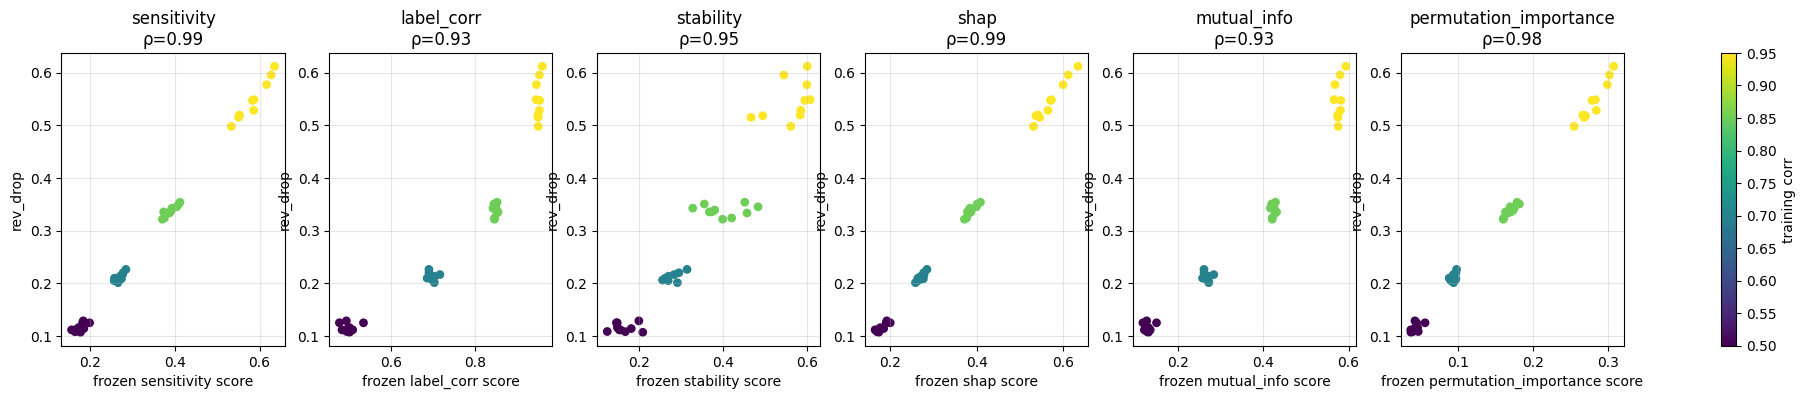

In [13]:
if SETTINGS["run_ood_after_freeze"]:
    core.verify_freeze(cfg)                      # refuses if scores are not frozen or were modified
    core.load_data(include_test=True)            # OOD data enters only now
    ood_long, ood_wide = core.ood_evaluate(cfg)  # writes ood_drops_long.csv and ood_drops.csv
    # analyze() overwrites analysis_spearman.csv on every call, so run the secondary target first,
    # keep a named copy of each, and finish with the primary target (cfg["target"]).
    _ = core.analyze(cfg, target="mean_drop", plot=False)
    shutil.copy(P["analysis"], f"{P['dir']}/analysis_spearman_mean_drop.csv")
    results, controls, blind, mixed = core.analyze(cfg)
    shutil.copy(P["analysis"], f"{P['dir']}/analysis_spearman_{cfg['target']}.csv")
else:
    print("Skipped (SETTINGS['run_ood_after_freeze'] is False).")

## Hand-off checklist

Everything is under `/kaggle/working/results/lr/`

- `runs_lr/scores_frozen.csv` (read-only) and `scores_frozen.manifest.json` (SHA-256 and config at freeze time)
- `runs_lr/run_meta.csv`, `runs_lr/models/` (LR needs no wrapper file to unpickle)
- `runs_lr/ood_drops.csv`, `ood_drops_long.csv`, `analysis_spearman.csv` (primary target) and `analysis_spearman_<target>.csv` copies
- `blind_detection_lr_v2.csv` (10 tasks, all six scores)
- `realism_check_lr.csv`
- `coef_regions_lr.csv` (exploratory weight view)
- `core.sha256` (check it matches the other model notebooks)

In [14]:
for root, _, files in sorted(os.walk(RESULTS_DIR)):
    rel = os.path.relpath(root, RESULTS_DIR)
    if rel.endswith("models") or rel.endswith("partial"):
        print(f"{rel}/  ({len(files)} files)"); continue
    for f in sorted(files):
        print(f if rel == "." else f"{rel}/{f}")

blind_detection_lr_v2.csv
coef_regions_lr.csv
core.sha256
realism_check_lr.csv
runs_lr/analysis_spearman.csv
runs_lr/analysis_spearman_mean_drop.csv
runs_lr/analysis_spearman_rev_drop.csv
runs_lr/ood_drops.csv
runs_lr/ood_drops_long.csv
runs_lr/run_meta.csv
runs_lr/scores_frozen.csv
runs_lr/scores_frozen.manifest.json
runs_lr/models/  (40 files)
runs_lr/partial/  (80 files)


In [15]:
import shutil

# Compress the /kaggle/working/results/lr directory into a zip archive
shutil.make_archive('/kaggle/working/results_lr', 'zip', '/kaggle/working/results/lr')
print("Successfully zipped the lr results!")

Successfully zipped the lr results!
